# Day 2 EDA: Instacart baskets and SKU-110K shelves

Run on the Azure ML compute instance with the **Python 3.10 - AzureML** kernel.
Expects Instacart CSVs in `~/data/raw/instacart` and SKU-110K in `~/datasets/SKU-110K`.

**Goal for today:** name three patterns in the Instacart data, understand the shelf images,
and save Instacart as Parquet for the mining and modelling days.

## Setup

In [1]:
import glob, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from PIL import Image

RAW = os.path.expanduser("~/data/raw/instacart")
PROC = os.path.expanduser("~/data/processed/instacart")
SKU = os.path.expanduser("~/datasets/SKU-110K")
os.makedirs(PROC, exist_ok=True)

# Chart style: one blue for single-series charts, recessive grid and axes, text in neutral ink.
BLUE = "#2a78d6"
SEQ_BLUE = LinearSegmentedColormap.from_list(
    "seq_blue", ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "text.color": "#0b0b0b",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e8e7e3", "grid.linewidth": 0.6,
    "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 12,
    "figure.dpi": 110,
})
os.listdir(RAW)

['order_products__train.csv',
 'order_products__prior.csv',
 'aisles.csv',
 'products.csv',
 'departments.csv',
 'orders.csv']

## 1. Load Instacart with compact dtypes

In [2]:
aisles = pd.read_csv(f"{RAW}/aisles.csv")
departments = pd.read_csv(f"{RAW}/departments.csv")
products = pd.read_csv(f"{RAW}/products.csv")
orders = pd.read_csv(f"{RAW}/orders.csv", dtype={
    "order_id": "int32", "user_id": "int32", "order_number": "int16",
    "order_dow": "int8", "order_hour_of_day": "int8", "days_since_prior_order": "float32"})
op_dtypes = {"order_id": "int32", "product_id": "int32", "add_to_cart_order": "int16", "reordered": "int8"}
prior = pd.read_csv(f"{RAW}/order_products__prior.csv", dtype=op_dtypes)
train = pd.read_csv(f"{RAW}/order_products__train.csv", dtype=op_dtypes)

products = products.merge(aisles, on="aisle_id").merge(departments, on="department_id")

for name, df in [("orders", orders), ("prior", prior), ("train", train), ("products", products)]:
    print(f"{name:9s} {df.shape[0]:>11,} rows  {df.memory_usage(deep=True).sum()/1e6:8.0f} MB")
print(orders["eval_set"].value_counts())
print("Missing days_since_prior_order (first orders):", orders["days_since_prior_order"].isna().sum())

orders      3,421,083 rows       267 MB
prior      32,434,489 rows       357 MB
train       1,384,617 rows        15 MB
products       49,688 rows        13 MB
prior    3214874
train     131209
test       75000
Name: eval_set, dtype: int64
Missing days_since_prior_order (first orders): 206209


## 2. Basket size

count    3214874.0
mean          10.1
std            7.5
min            1.0
25%            5.0
50%            8.0
75%           14.0
max          145.0
dtype: float64


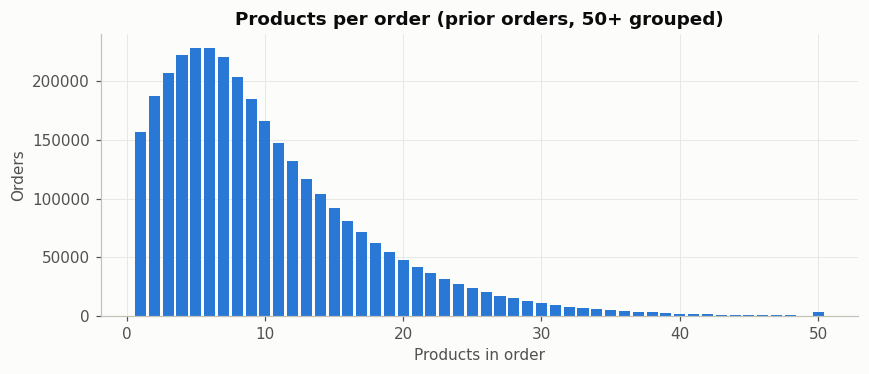

In [3]:
basket = prior.groupby("order_id").size()
print(basket.describe().round(1))

fig, ax = plt.subplots(figsize=(8, 3.5))
counts = basket.clip(upper=50).value_counts().sort_index()
ax.bar(counts.index, counts.values, width=0.8, color=BLUE)
ax.set(title="Products per order (prior orders, 50+ grouped)", xlabel="Products in order", ylabel="Orders")
plt.tight_layout(); plt.show()

## 3. Top products

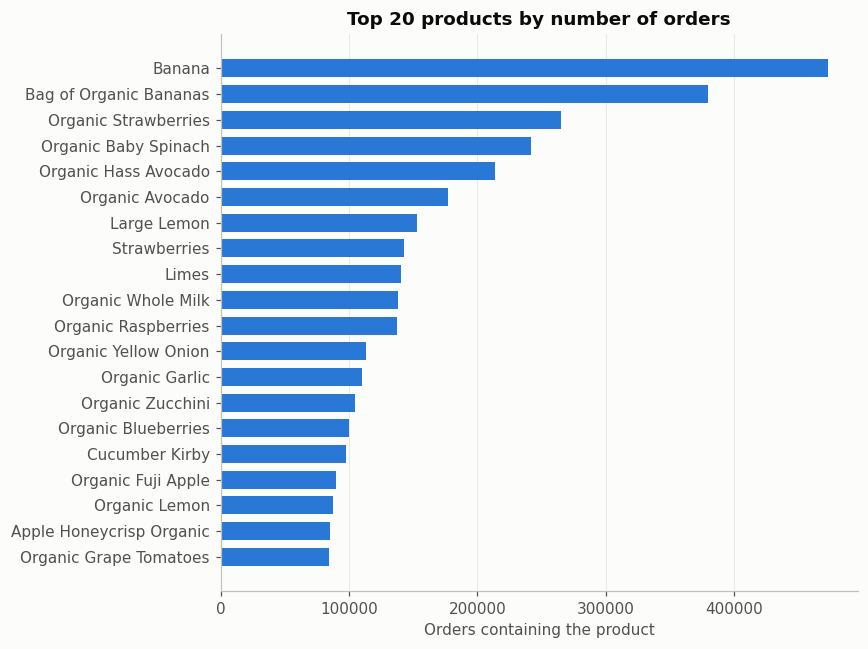

,product_name,department,orders
0,Banana,produce,472565
1,Bag of Organic Bananas,produce,379450
2,Organic Strawberries,produce,264683
3,Organic Baby Spinach,produce,241921
4,Organic Hass Avocado,produce,213584
5,Organic Avocado,produce,176815
6,Large Lemon,produce,152657
7,Strawberries,produce,142951
8,Limes,produce,140627
9,Organic Whole Milk,dairy eggs,137905


In [4]:
top = (prior["product_id"].value_counts().head(20)
       .rename_axis("product_id").reset_index(name="orders")
       .merge(products[["product_id", "product_name", "department"]], on="product_id"))

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top["product_name"][::-1], top["orders"][::-1], height=0.7, color=BLUE)
ax.set(title="Top 20 products by number of orders", xlabel="Orders containing the product")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()
top[["product_name", "department", "orders"]]

## 4. Reorder rate by department

Overall reorder rate: 59.0%


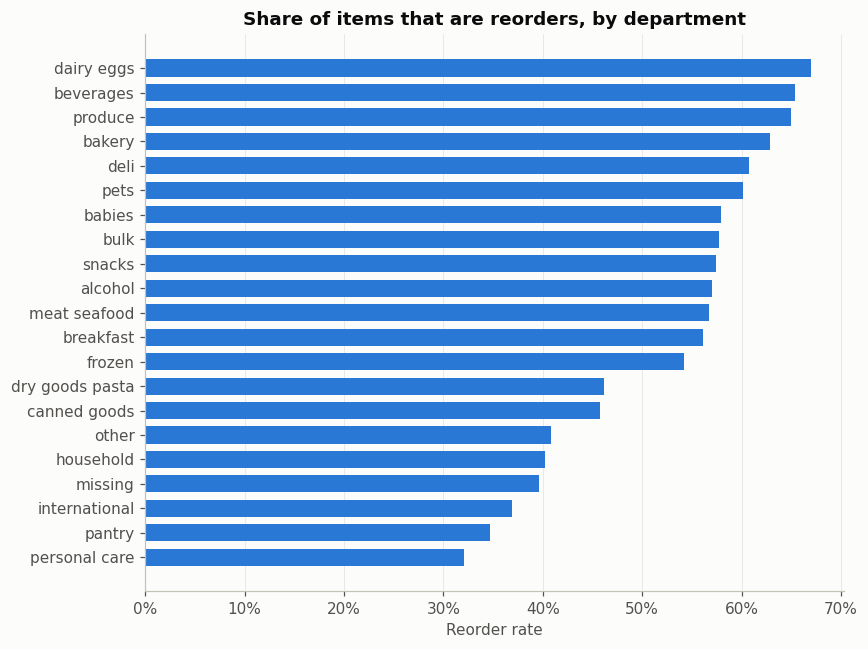

In [5]:
dept_of = products.set_index("product_id")["department"]
prior["department"] = prior["product_id"].map(dept_of).astype("category")
print(f"Overall reorder rate: {prior['reordered'].mean():.1%}")

dept = prior.groupby("department", observed=True)["reordered"].agg(["mean", "size"]).sort_values("mean")
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(dept.index.astype(str), dept["mean"], height=0.7, color=BLUE)
ax.set(title="Share of items that are reorders, by department", xlabel="Reorder rate")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

## 5. When people order

`order_dow` is 0–6. The dataset doesn't document which day 0 is (often assumed Sunday), so the labels stay numeric.

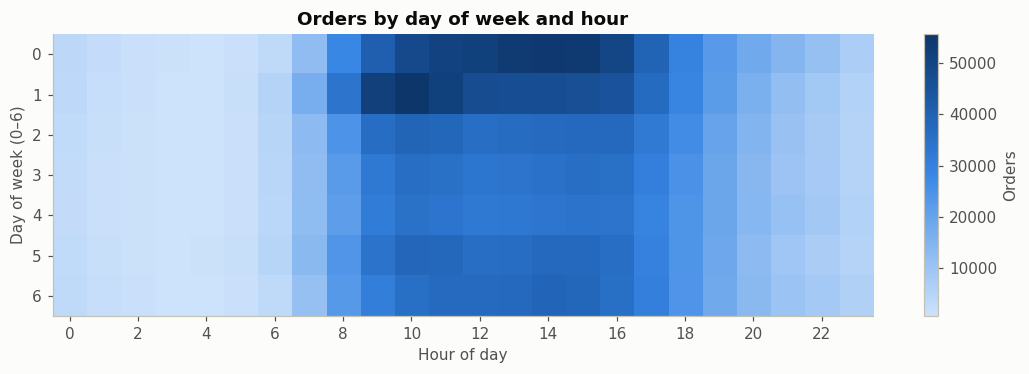

In [6]:
heat = orders.pivot_table(index="order_dow", columns="order_hour_of_day",
                          values="order_id", aggfunc="count")
fig, ax = plt.subplots(figsize=(10, 3.5))
im = ax.imshow(heat.values, aspect="auto", cmap=SEQ_BLUE)
ax.set(title="Orders by day of week and hour", xlabel="Hour of day", ylabel="Day of week (0–6)",
       xticks=range(0, 24, 2), yticks=range(7))
ax.grid(False)
fig.colorbar(im, ax=ax, label="Orders")
plt.tight_layout(); plt.show()

## 6. Time between orders

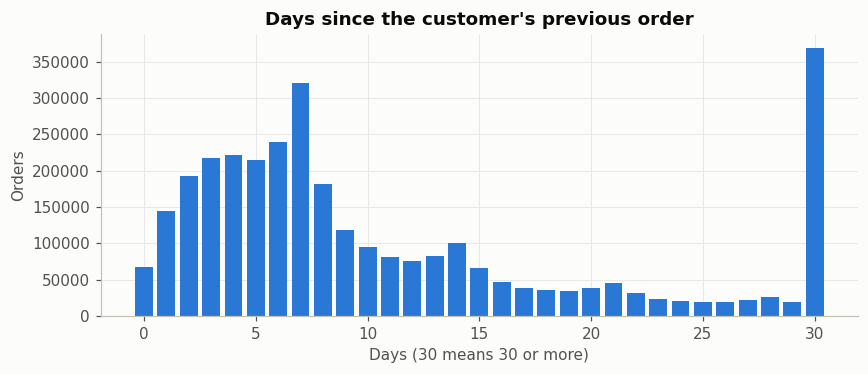

Orders per user:
count    206209.0
mean         16.6
std          16.7
min           4.0
25%           6.0
50%          10.0
75%          20.0
max         100.0
dtype: float64


In [7]:
gap = orders["days_since_prior_order"].dropna().astype(int).value_counts().sort_index()
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(gap.index, gap.values, width=0.8, color=BLUE)
ax.set(title="Days since the customer's previous order", xlabel="Days (30 means 30 or more)", ylabel="Orders")
plt.tight_layout(); plt.show()

per_user = orders.groupby("user_id").size()
print("Orders per user:"); print(per_user.describe().round(1))

## 7. Three patterns (write these in your own words)

Fill this in from the charts above; it goes straight into the README and LOG.md.

1. **Basket size:** …
2. **Reorders:** … (which departments are habitual, which are one-off?)
3. **Timing:** … (peak days and hours, and what the spikes at 7 and 30 days suggest)

## 8. Save Instacart as Parquet

In [8]:
prior = prior.drop(columns="department")
products.to_parquet(f"{PROC}/products.parquet", index=False)
orders.to_parquet(f"{PROC}/orders.parquet", index=False)
prior.to_parquet(f"{PROC}/order_products_prior.parquet", index=False)
train.to_parquet(f"{PROC}/order_products_train.parquet", index=False)
for f in sorted(os.listdir(PROC)):
    print(f"{f:32s} {os.path.getsize(os.path.join(PROC, f))/1e6:7.1f} MB")

order_products_prior.parquet       117.5 MB
order_products_train.parquet         5.0 MB
orders.parquet                      25.2 MB
products.parquet                     1.2 MB


## 9. SKU-110K: boxes per image and box sizes

YOLO labels are one line per box: `class x_center y_center width height`, all normalised to 0–1.

        count   mean   std   min    25%    50%    75%    max
split                                                       
test   2936.0  147.0  41.0  20.0  123.0  137.0  161.0  533.0
train  8219.0  147.0  43.0   1.0  123.0  138.0  161.0  576.0
val     588.0  155.0  60.0  40.0  124.0  139.0  167.0  718.0
Images with more than 300 boxes: 1.1%  (why training uses max_det=1000)


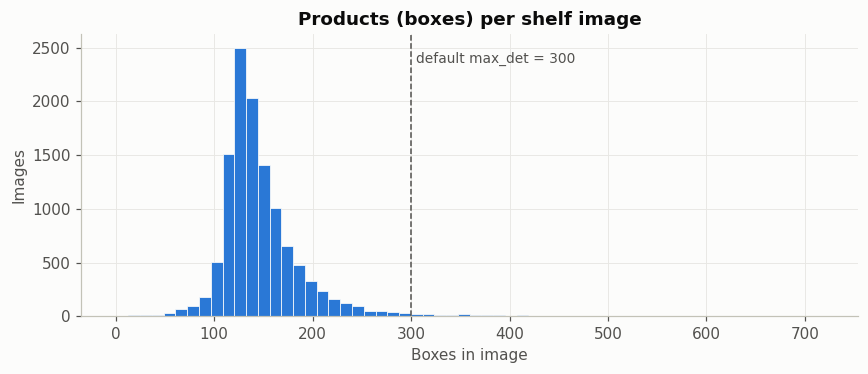

Typical box size as a share of image width/height:
          mean_w     mean_h
count  11743.000  11743.000
mean       0.051      0.063
std        0.019      0.021
min        0.010      0.014
25%        0.040      0.047
50%        0.047      0.064
75%        0.057      0.078
max        0.193      0.223


In [9]:
label_files = glob.glob(f"{SKU}/labels/*.txt")
rows = []
for lf in label_files:
    arr = np.loadtxt(lf, ndmin=2)
    split = os.path.basename(lf).split("_")[0]
    rows.append((os.path.basename(lf), split, len(arr),
                 arr[:, 3].mean() if len(arr) else np.nan, arr[:, 4].mean() if len(arr) else np.nan))
sku = pd.DataFrame(rows, columns=["file", "split", "boxes", "mean_w", "mean_h"])
print(sku.groupby("split")["boxes"].describe().round(0))
print(f"Images with more than 300 boxes: {(sku['boxes'] > 300).mean():.1%}  (why training uses max_det=1000)")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(sku["boxes"], bins=60, color=BLUE, edgecolor="#fcfcfb", linewidth=0.5)
ax.axvline(300, color="#52514e", linestyle="--", linewidth=1)
ax.text(305, ax.get_ylim()[1] * 0.9, "default max_det = 300", color="#52514e", fontsize=9)
ax.set(title="Products (boxes) per shelf image", xlabel="Boxes in image", ylabel="Images")
plt.tight_layout(); plt.show()

print("Typical box size as a share of image width/height:")
print(sku[["mean_w", "mean_h"]].describe().round(3))

In [10]:
sizes = pd.Series([Image.open(p).size for p in
                   pd.Series(glob.glob(f"{SKU}/images/*.jpg")).sample(500, random_state=0)])
print("Most common image sizes (width, height):")
print(sizes.value_counts().head(5))

Most common image sizes (width, height):
(2448, 3264)    211
(1920, 2560)    115
(2336, 4160)     34
(2340, 4160)     28
(3264, 2448)     22
dtype: int64


## 10. Look at two shelves with their labels

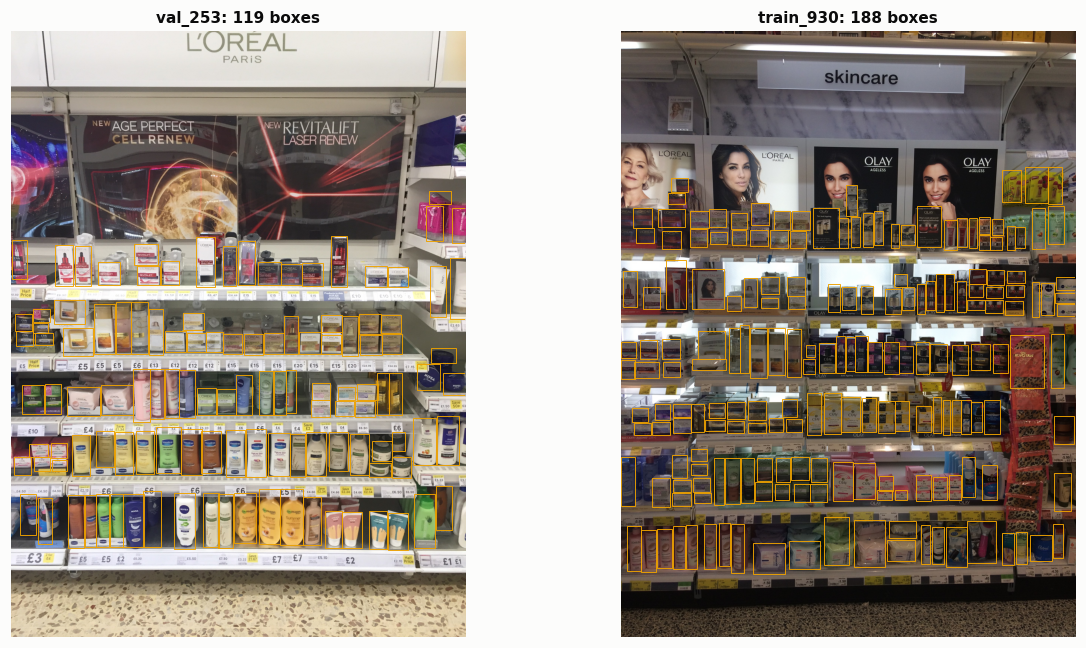

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, row in zip(axes, sku.sample(2, random_state=1).itertuples()):
    img = Image.open(f"{SKU}/images/{row.file.replace('.txt', '.jpg')}")
    W, H = img.size
    ax.imshow(img); ax.axis("off"); ax.grid(False)
    for _, xc, yc, w, h in np.loadtxt(f"{SKU}/labels/{row.file}", ndmin=2):
        ax.add_patch(plt.Rectangle(((xc - w/2) * W, (yc - h/2) * H), w * W, h * H,
                                   fill=False, edgecolor="#eda100", linewidth=0.6))
    ax.set_title(f"{row.file.replace('.txt', '')}: {row.boxes} boxes", fontsize=10)
plt.tight_layout(); plt.show()

## 11. Upload the Parquet files to Azure (run in the terminal)

```bash
azcopy copy "$HOME/data/processed/instacart/*" \
  "https://stretail26561.blob.core.windows.net/retail-data/processed/instacart/" --recursive

az ml data create -n instacart-processed --type uri_folder --path azureml://datastores/retaildata/paths/processed/instacart/ -g rg-retail -w mlw-retail
```